<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

<a href="https://query.farm/vgi/"><img src="assets/vgi-logo.png" alt="VGI — Vector Gateway Interface" width="280"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Haybarn](https://query.farm/products/haybarn/) · [Setup guide](README.md)

# 01 · One report, mixed units

**Can we compare three process skids when their instruments report different units?**
Cedar reports Celsius and bar, Harbor uses Fahrenheit and psi, and Mesa uses Kelvin
and kPa. Their sampled volumes use litres, US gallons and millilitres. We will
build one report without losing invalid records or confusing a temperature with
a temperature rise.

**Data: synthetic.** Every input is defined below for one hypothetical sampling
round, with no acquisition timestamp. These are teaching values, not equipment
telemetry, operating limits or efficiency measurements. Pressure readings are
assumed to share an absolute reference; unit conversion cannot reconcile gauge
and absolute readings without that extra information. A sampled volume is not
a flow rate. The real Rust worker supplies every unit definition and conversion.

## Choose the reporting temperature scale

The default reports absolute temperatures in **°F** and temperature changes in
**Δ°F**. Accepted strings are `"°C"`, `"°F"`, and `"K"`; Kelvin has no degree symbol.
Pressure stays in kPa and sample volume stays in L. Edit the parameter, then
**Restart Kernel → Run All**. The end experiment changes only this scale to `"K"`.
[Environment and kernel instructions](README.md#install-and-run) live in the guide.

In [1]:
REPORT_TEMP_UNIT = "°F"  # "°C", "°F", or "K"; reporting scale, not a physical change

In [2]:
from pathlib import Path
import os
import sys

os.environ["PLOOMBER_STATS_ENABLED"] = "false"
NOTEBOOK_DIR = (
    Path.cwd()
    if (Path.cwd() / "notebook_support.py").is_file()
    else Path.cwd() / "notebooks"
)
sys.path.insert(0, str(NOTEBOOK_DIR))
import haybarn
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from notebook_support import COLORS, SOURCE, chart, prose, set_theme, sql_text

if REPORT_TEMP_UNIT not in {"°C", "°F", "K"}:
    raise ValueError('REPORT_TEMP_UNIT must be one of "°C", "°F", or "K".')
report_unit_sql = sql_text(REPORT_TEMP_UNIT)
set_theme()
con = haybarn.connect(config={"TimeZone": "UTC"})
%load_ext sql
%config SqlMagic.autopandas = True
%config SqlMagic.feedback = False
%config SqlMagic.displaycon = False
%sql con
%matplotlib inline

Tip: You may define configurations in /private/var/folders/5z/17gt9js944s7smk125j23jr80000gn/T/vgi-units-portable-l6tvsb7r/notebooks/pyproject.toml or /Users/rusty/.jupysql/config.

Did not find user configurations in /private/var/folders/5z/17gt9js944s7smk125j23jr80000gn/T/vgi-units-portable-l6tvsb7r/notebooks/pyproject.toml.

## Connect to the conversion engine

The literal `github-auto` location fetches the published **v0.4.0 Rust binary**
for this platform, verifies its SHA-256 sidecar, and runs it through VGI. No Rust
compiler or worker checkout is required. Initial dependency, extension and worker
downloads need network access; the calculations use only the synthetic inputs.

This release exposes `convert`, `to_base` and `supported_units`; the newer strict
conversion functions and `unit_catalog` are not in its binary. We therefore audit
labels before conversion and explicitly cancel offsets for temperature changes.
Ordinary in-memory tables are shared by JupySQL's cursors.

In [3]:
%%sql
INSTALL vgi FROM community;
LOAD vgi;
ATTACH 'units' (TYPE vgi, LOCATION 'github-auto://Query-farm/vgi-units@v0.4.0');
SELECT extension_name, extension_version, loaded
FROM duckdb_extensions() WHERE extension_name = 'vgi';

,extension_name,extension_version,loaded
0,vgi,e75482339d,True


In [4]:
prose(
    f"**Local synthetic run · report temperature: {REPORT_TEMP_UNIT}.** "
    "Worker: published Rust release `v0.4.0`; the github-auto transport verifies its SHA-256 sidecar. "
    "No measurements are fetched from a service."
)

**Local synthetic run · report temperature: °F.** Worker: published Rust release `v0.4.0`; the github-auto transport verifies its SHA-256 sidecar. No measurements are fetched from a service.

## Discover what can be compared

The worker's supported-unit table is the authority for recognized units, dimensions
and base units. We retain it once, then define our report policy. Compatible units
share a dimension; compatibility alone does not tell us whether a temperature
value is absolute or a difference. The release's public functions also let us
measure each conversion's affine factor and offset, later in the walkthrough.

In [5]:
%%sql
CREATE OR REPLACE TABLE catalog AS SELECT * FROM units.main.supported_units();
CREATE OR REPLACE TABLE reporting_policy AS
SELECT * FROM (VALUES
    ('pressure', 'pressure', 'kPa'),
    ('sample_volume', 'volume', 'L'),
    ('inlet', 'temperature', {{ report_unit_sql }}),
    ('outlet', 'temperature', {{ report_unit_sql }})
) p(metric, expected_dimension, report_unit);
SELECT p.metric, p.report_unit, c.dimension, c.base_unit
FROM reporting_policy p JOIN catalog c ON c.unit = p.report_unit
ORDER BY p.metric;

,metric,report_unit,dimension,base_unit
0,inlet,°F,temperature,K
1,outlet,°F,temperature,K
2,pressure,kPa,pressure,Pa
3,sample_volume,L,volume,m^3


In [6]:
%%sql compatibility <<
SELECT candidate_unit,
       units.main.dimension(candidate_unit) AS dimension,
       units.main.compatible(candidate_unit, 'kPa') AS pressure_report,
       units.main.compatible(candidate_unit, 'L') AS volume_report,
       units.main.compatible(candidate_unit, {{ report_unit_sql }}) AS temperature_report
FROM (VALUES ('bar'), ('psi'), ('gal'), ('mL'), ('°C'), ('K'), ('kg'), ('buckets')) t(candidate_unit);

In [7]:
display(compatibility)
known = compatibility.dimension.notna().sum()
prose(
    f"The candidate list contains **{known} recognized unit strings**. "
    "A recognized mass unit still cannot populate a pressure field; an unknown label "
    "does not match any report dimension. The temperature rows are compatible, "
    "but absolute temperatures and temperature differences need different treatment."
)

,candidate_unit,dimension,pressure_report,volume_report,temperature_report
0,bar,pressure,True,False,False
1,psi,pressure,True,False,False
2,gal,volume,False,True,False
3,mL,volume,False,True,False
4,°C,temperature,False,False,True
5,K,temperature,False,False,True
6,kg,mass,False,False,False
7,buckets,None,False,False,False


The candidate list contains **7 recognized unit strings**. A recognized mass unit still cannot populate a pressure field; an unknown label does not match any report dimension. The temperature rows are compatible, but absolute temperatures and temperature differences need different treatment.

## Keep the input audit beside the report

The first twelve rows describe the three sites. Five extra rows deliberately test
wrong dimensions, unknown units, missing text, malformed text and a valid zero
reference. Those diagnostic rows are outside the operating comparison.

`parse_quantity` returns a value/unit struct or NULL. Unknown units and malformed
text both produce NULL, so the audit groups them as **unparsed / unknown**. It
keeps missing source text and incompatible recognized units separate.

In [8]:
%%sql
CREATE OR REPLACE TABLE raw_readings AS
SELECT * FROM (VALUES
    (1,  'Cedar', 'operating', 'pressure',      '2.4 bar'),
    (2,  'Cedar', 'operating', 'sample_volume', '12 L'),
    (3,  'Cedar', 'operating', 'inlet',         '20 °C'),
    (4,  'Cedar', 'operating', 'outlet',        '30 °C'),
    (5,  'Harbor','operating', 'pressure',      '36 psi'),
    (6,  'Harbor','operating', 'sample_volume', '3 gal'),
    (7,  'Harbor','operating', 'inlet',         '68 °F'),
    (8,  'Harbor','operating', 'outlet',        '95 °F'),
    (9,  'Mesa',  'operating', 'pressure',      '250 kPa'),
    (10, 'Mesa',  'operating', 'sample_volume', '12500 mL'),
    (11, 'Mesa',  'operating', 'inlet',         '293.15 K'),
    (12, 'Mesa',  'operating', 'outlet',        '308.15 K'),
    (13, 'Spare', 'diagnostic','pressure',      '5 kg'),
    (14, 'Spare', 'diagnostic','sample_volume', '3 buckets'),
    (15, 'Spare', 'diagnostic','inlet',         NULL),
    (16, 'Spare', 'diagnostic','outlet',        'sensor offline'),
    (17, 'Zero reference','diagnostic','inlet', '0 °C')
) t(reading_id, site, record_kind, metric, raw_quantity);
CREATE OR REPLACE TABLE parsed_readings AS
SELECT *, units.main.parse_quantity(raw_quantity) AS quantity FROM raw_readings;
CREATE OR REPLACE TABLE audited_readings AS
SELECT r.*, quantity.value AS source_value, quantity.unit AS source_unit,
       p.report_unit, units.main.dimension(quantity.unit) AS source_dimension,
       CASE WHEN raw_quantity IS NULL THEN 'missing'
            WHEN quantity IS NULL THEN 'unparsed / unknown'
            WHEN NOT units.main.compatible(quantity.unit, p.report_unit) THEN 'incompatible'
            ELSE 'accepted' END AS status
FROM parsed_readings r JOIN reporting_policy p USING (metric);
SELECT reading_id, site, metric, raw_quantity, source_value, source_unit,
       report_unit, status
FROM audited_readings ORDER BY reading_id;

,reading_id,site,metric,raw_quantity,source_value,source_unit,report_unit,status
0,1,Cedar,pressure,2.4 bar,2.40,bar,kPa,accepted
1,2,Cedar,sample_volume,12 L,12.00,L,L,accepted
2,3,Cedar,inlet,20 °C,20.00,°C,°F,accepted
3,4,Cedar,outlet,30 °C,30.00,°C,°F,accepted
4,5,Harbor,pressure,36 psi,36.00,psi,kPa,accepted
5,6,Harbor,sample_volume,3 gal,3.00,gal,L,accepted
6,7,Harbor,inlet,68 °F,68.00,°F,°F,accepted
7,8,Harbor,outlet,95 °F,95.00,°F,°F,accepted
8,9,Mesa,pressure,250 kPa,250.00,kPa,kPa,accepted
9,10,Mesa,sample_volume,12500 mL,12500.00,mL,L,accepted


In [9]:
%%sql quality <<
SELECT status, count(*) AS readings FROM audited_readings GROUP BY status ORDER BY status;

In [10]:
display(quality)
counts = quality.set_index("status").readings
accepted_count = int(counts.get("accepted", 0))
prose(
    f"**{accepted_count} of {int(counts.sum())} readings are eligible for conversion.** "
    f"The remaining {int(counts.sum()) - accepted_count} stay in the audit. "
    "A parsed zero remains accepted; absence and bad units do not become zero. "
    "We materialize accepted rows before conversion, so incompatible dimensions never "
    "reach the conversion batch. Unknown units can return NULL; the checks below require complete accepted results. These checks validate labels and dimensions, not sensor accuracy."
)

,status,readings
0,accepted,13
1,incompatible,1
2,missing,1
3,unparsed / unknown,2


**13 of 17 readings are eligible for conversion.** The remaining 4 stay in the audit. A parsed zero remains accepted; absence and bad units do not become zero. We materialize accepted rows before conversion, so incompatible dimensions never reach the conversion batch. Unknown units can return NULL; the checks below require complete accepted results. These checks validate labels and dimensions, not sensor accuracy.

## Normalize the accepted measurements

All readings here are absolute quantities. `convert` applies the scale factor
and any temperature offset. In v0.4.0 it returns NULL for unknown units and errors
on incompatible known dimensions. The preceding audit materializes only recognized,
compatible pairs, and the final checks require complete conversion results.
`to_base` provides a second view in each dimension's base unit.

The worker defines `gal` as a US liquid gallon. These pressure inputs are assumed
to use the same reference, and we keep volume separate from pressure; their
magnitudes cannot be pooled into a single score.

In [11]:
%%sql
CREATE OR REPLACE TABLE accepted_readings AS
SELECT * FROM audited_readings WHERE status = 'accepted';
CREATE OR REPLACE TABLE normalized_readings AS
SELECT *, units.main.convert(source_value, source_unit, report_unit) AS report_value,
       units.main.to_base(source_value, source_unit) AS base_value
FROM accepted_readings;
SELECT site, metric, raw_quantity, round(report_value, 4) AS report_value, report_unit
FROM normalized_readings ORDER BY reading_id;

,site,metric,raw_quantity,report_value,report_unit
0,Cedar,pressure,2.4 bar,240.0000,kPa
1,Cedar,sample_volume,12 L,12.0000,L
2,Cedar,inlet,20 °C,68.0000,°F
3,Cedar,outlet,30 °C,86.0000,°F
4,Harbor,pressure,36 psi,248.2113,kPa
5,Harbor,sample_volume,3 gal,11.3562,L
6,Harbor,inlet,68 °F,68.0000,°F
7,Harbor,outlet,95 °F,95.0000,°F
8,Mesa,pressure,250 kPa,250.0000,kPa
9,Mesa,sample_volume,12500 mL,12.5000,L


In [12]:
%%sql mechanical <<
SELECT site, metric, raw_quantity, report_value, report_unit
FROM normalized_readings
WHERE record_kind = 'operating' AND metric IN ('pressure', 'sample_volume')
ORDER BY site, metric;

findfont: Failed to find font weight semibold for Arial, now using 700.


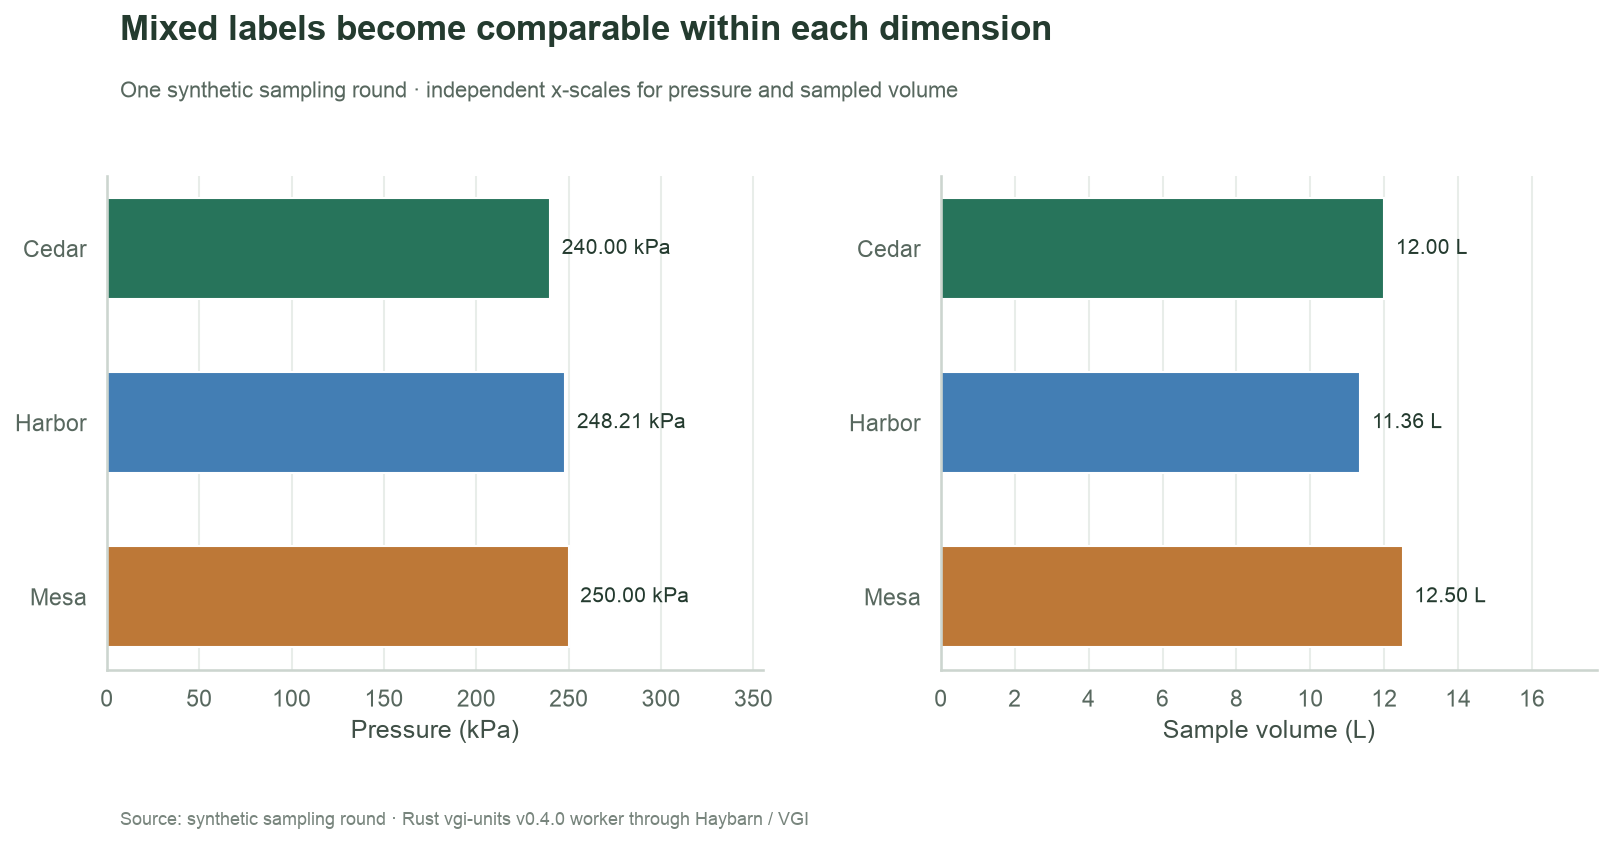

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(11, 5.6))
for ax, metric, label in zip(
    axes, ["pressure", "sample_volume"], ["Pressure (kPa)", "Sample volume (L)"]
):
    rows = mechanical[mechanical.metric == metric].sort_values("site")
    positions = np.arange(len(rows))
    ax.barh(
        positions, rows.report_value, color=[COLORS[s] for s in rows.site], height=0.58
    )
    ax.set_yticks(positions, rows.site)
    ax.invert_yaxis()
    ax.set(xlabel=label, ylabel="", xlim=(0, rows.report_value.max() * 1.42))
    ax.grid(axis="y", visible=False)
    for position, row in zip(positions, rows.itertuples()):
        ax.text(
            row.report_value + rows.report_value.max() * 0.025,
            position,
            f"{row.report_value:.2f} {row.report_unit}",
            va="center",
            fontsize=10,
        )
chart(
    fig,
    "Mixed labels become comparable within each dimension",
    "One synthetic sampling round · independent x-scales for pressure and sampled volume",
)

In [14]:
pressure = mechanical[mechanical.metric == "pressure"].sort_values("report_value")
volume = mechanical[mechanical.metric == "sample_volume"].sort_values("report_value")
prose(
    f"The pressure readings span **{pressure.report_value.min():.2f}–{pressure.report_value.max():.2f} kPa**. "
    f"{volume.iloc[-1].site} has the largest sampled volume in this example "
    f"(**{volume.report_value.max():.2f} L**). "
    "The comparison is now dimensionally meaningful, but it does not establish an operating limit "
    "or a throughput ranking: we did not observe elapsed sampling time."
)

The pressure readings span **240.00–250.00 kPa**. Mesa has the largest sampled volume in this example (**12.50 L**). The comparison is now dimensionally meaningful, but it does not establish an operating limit or a throughput ranking: we did not observe elapsed sampling time.

## A temperature rise is a difference between two temperatures

The next query pairs each site's inlet and outlet. We first normalize both
absolute temperatures to °C. To convert a **difference**, SQL subtracts
`convert(0, source, target)` from `convert(difference, source, target)`. For an
affine conversion this cancels the offset and leaves only the scale factor.
Subtracting the two absolute endpoint values in the report scale must give the
same rise; that is a useful cross-check using a different pair of inputs.

The report below only includes sites with both readings. Missing pairs would be
shown by the coverage query, never as a zero rise.

In [15]:
%%sql
CREATE OR REPLACE TABLE thermal_pairs AS
SELECT site,
       max(CASE WHEN metric = 'inlet' THEN report_value END) AS inlet_report,
       max(CASE WHEN metric = 'outlet' THEN report_value END) AS outlet_report,
       max(CASE WHEN metric = 'inlet'
           THEN units.main.convert(source_value, source_unit, '°C') END) AS inlet_c,
       max(CASE WHEN metric = 'outlet'
           THEN units.main.convert(source_value, source_unit, '°C') END) AS outlet_c
FROM normalized_readings
WHERE record_kind = 'operating' AND metric IN ('inlet', 'outlet')
GROUP BY site;
SELECT r.site,
       count(*) FILTER (WHERE r.metric IN ('inlet', 'outlet') AND a.status = 'accepted') AS accepted_temperature_readings,
       CASE WHEN t.inlet_report IS NOT NULL AND t.outlet_report IS NOT NULL
            THEN 'paired' ELSE 'incomplete; excluded from temperature chart' END AS temperature_coverage
FROM raw_readings r JOIN audited_readings a USING (reading_id)
LEFT JOIN thermal_pairs t ON r.site = t.site
WHERE r.record_kind = 'operating'
GROUP BY r.site, t.inlet_report, t.outlet_report ORDER BY r.site;

,site,accepted_temperature_readings,temperature_coverage
0,Cedar,2,paired
1,Harbor,2,paired
2,Mesa,2,paired


In [16]:
%%sql thermal <<
CREATE OR REPLACE TABLE thermal_report AS
SELECT *, outlet_c - inlet_c AS rise_c,
       (units.main.convert(outlet_c - inlet_c, '°C', {{ report_unit_sql }})
        - units.main.convert(0, '°C', {{ report_unit_sql }})) AS rise_report,
       outlet_report - inlet_report AS rise_from_endpoints
FROM thermal_pairs WHERE inlet_report IS NOT NULL AND outlet_report IS NOT NULL;
SELECT * FROM thermal_report ORDER BY site;

,site,Inlet (°F),Outlet (°F),Rise (Δ°F)
0,Cedar,68.0,86.0,18.0
1,Harbor,68.0,95.0,27.0
2,Mesa,68.0,95.0,27.0


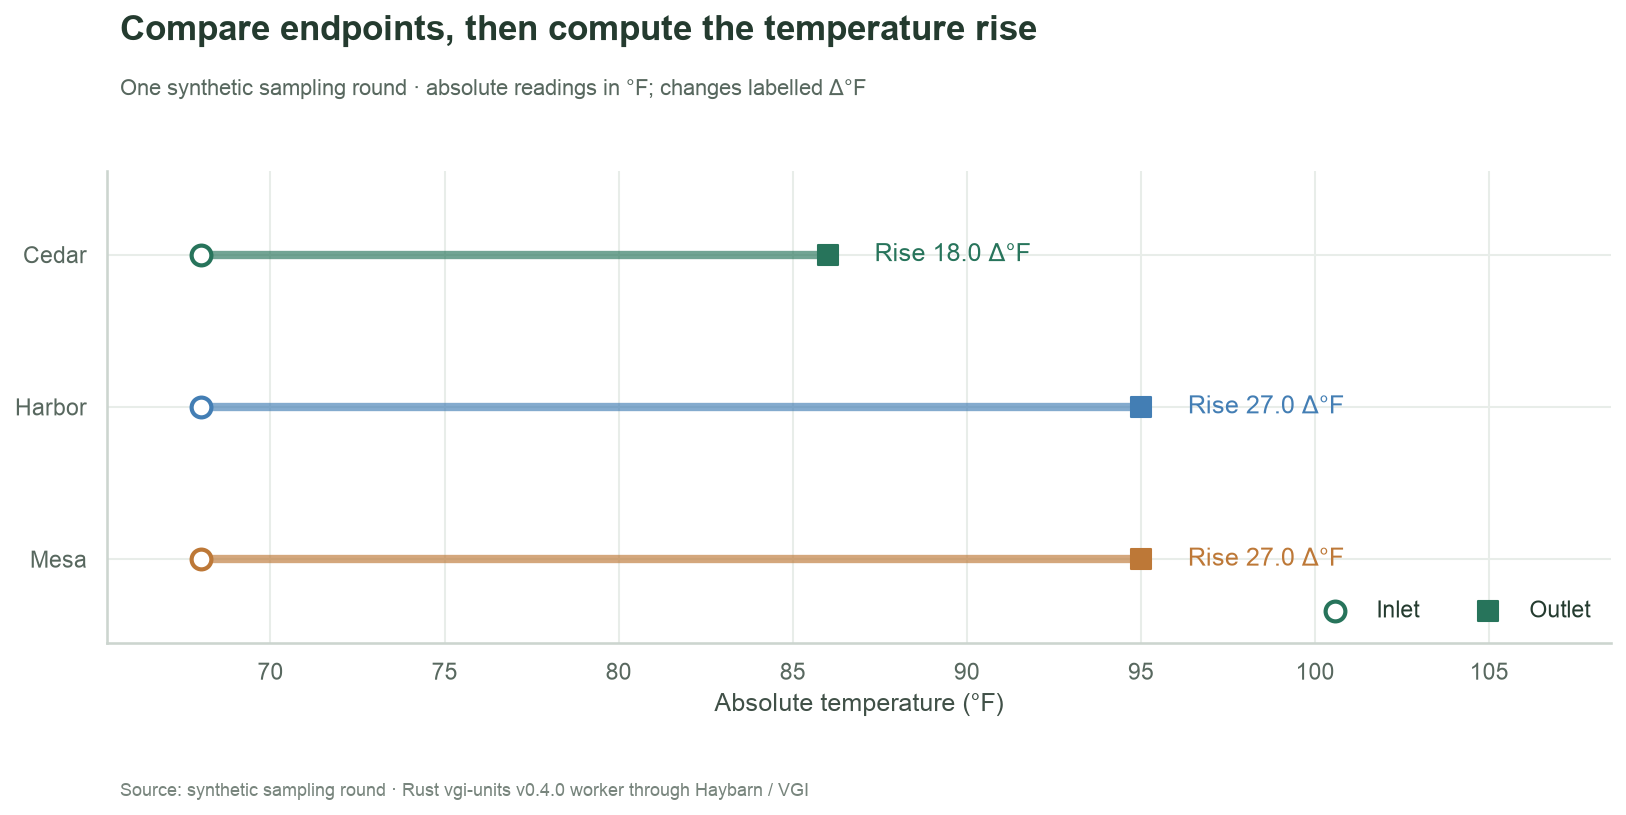

In [17]:
display(
    thermal[["site", "inlet_report", "outlet_report", "rise_report"]].rename(
        columns={
            "inlet_report": f"Inlet ({REPORT_TEMP_UNIT})",
            "outlet_report": f"Outlet ({REPORT_TEMP_UNIT})",
            "rise_report": f"Rise (Δ{REPORT_TEMP_UNIT})",
        }
    )
)
if thermal.empty:
    prose(
        "**Temperature chart unavailable:** no site has a complete pair of accepted readings."
    )
else:
    fig, ax = plt.subplots(figsize=(11, 5.4))
    lo = min(thermal.inlet_report.min(), thermal.outlet_report.min())
    hi = max(thermal.inlet_report.max(), thermal.outlet_report.max())
    span = max(hi - lo, 1)
    for y, row in enumerate(thermal.itertuples()):
        color = COLORS[row.site]
        ax.plot(
            [row.inlet_report, row.outlet_report], [y, y], color=color, lw=4, alpha=0.65
        )
        ax.scatter(
            row.inlet_report,
            y,
            s=90,
            facecolors="white",
            edgecolors=color,
            linewidth=2,
            zorder=3,
            label="Inlet" if y == 0 else None,
        )
        ax.scatter(
            row.outlet_report,
            y,
            s=90,
            color=color,
            marker="s",
            zorder=3,
            label="Outlet" if y == 0 else None,
        )
        ax.text(
            max(row.inlet_report, row.outlet_report) + span * 0.05,
            y,
            f"Rise {row.rise_report:.1f} Δ{REPORT_TEMP_UNIT}",
            va="center",
            color=color,
        )
    ax.set_yticks(range(len(thermal)), thermal.site)
    ax.set(
        xlabel=f"Absolute temperature ({REPORT_TEMP_UNIT})",
        ylabel="",
        xlim=(lo - span * 0.1, hi + span * 0.5),
        ylim=(-0.55, len(thermal) - 0.45),
    )
    ax.invert_yaxis()
    ax.legend(loc="lower right", ncol=2)
    chart(
        fig,
        "Compare endpoints, then compute the temperature rise",
        f"One synthetic sampling round · absolute readings in {REPORT_TEMP_UNIT}; changes labelled Δ{REPORT_TEMP_UNIT}",
    )

In [18]:
if not thermal.empty:
    maximum = thermal.rise_report.max()
    leaders = ", ".join(thermal.loc[np.isclose(thermal.rise_report, maximum), "site"])
    prose(
        f"**{leaders}** share the largest rise in these inputs: **{maximum:.1f} Δ{REPORT_TEMP_UNIT}**. "
        "The rise is the outlet minus inlet, not the converted outlet alone. "
        "Equal temperature rises do not imply equal heat transfer: mass flow, fluid properties "
        "and measurement uncertainty are outside this example."
    )

**Harbor, Mesa** share the largest rise in these inputs: **27.0 Δ°F**. The rise is the outlet minus inlet, not the converted outlet alone. Equal temperature rises do not imply equal heat transfer: mass flow, fluid properties and measurement uncertainty are outside this example.

## See the offset error directly

For these units, absolute conversion has the form `base = value × factor + offset`.
The release does not expose an affine-constant table, so we measure the offset
with `to_base(0, unit)` and the factor with `to_base(1, unit) - to_base(0, unit)`.
These are derived probes of the worker, not manually entered constants.

We then convert hypothetical Celsius changes with and without offset cancellation.
The dashed curve deliberately mislabels each change as an absolute Celsius
temperature. It illustrates a mistake, not an alternative estimate.

In [19]:
%%sql
SELECT unit, dimension, base_unit,
       units.main.to_base(1, unit) - units.main.to_base(0, unit) AS measured_factor,
       units.main.to_base(0, unit) AS measured_offset
FROM catalog WHERE unit IN ('°C', '°F', 'K') ORDER BY unit;

,unit,dimension,base_unit,measured_factor,measured_offset
0,K,temperature,K,1.00000,0.00000
1,°C,temperature,K,1.00000,273.15000
2,°F,temperature,K,0.55556,255.37222


In [20]:
%%sql difference_curve <<
CREATE OR REPLACE TABLE difference_comparison AS
SELECT change_c,
       (units.main.convert(change_c, '°C', {{ report_unit_sql }})
        - units.main.convert(0, '°C', {{ report_unit_sql }})) AS correct_difference,
       units.main.convert(change_c, '°C', {{ report_unit_sql }}) AS absolute_misapplied
FROM (SELECT range::DOUBLE AS change_c FROM range(-10, 26)) t;
SELECT *, absolute_misapplied - correct_difference AS offset_error
FROM difference_comparison ORDER BY change_c;

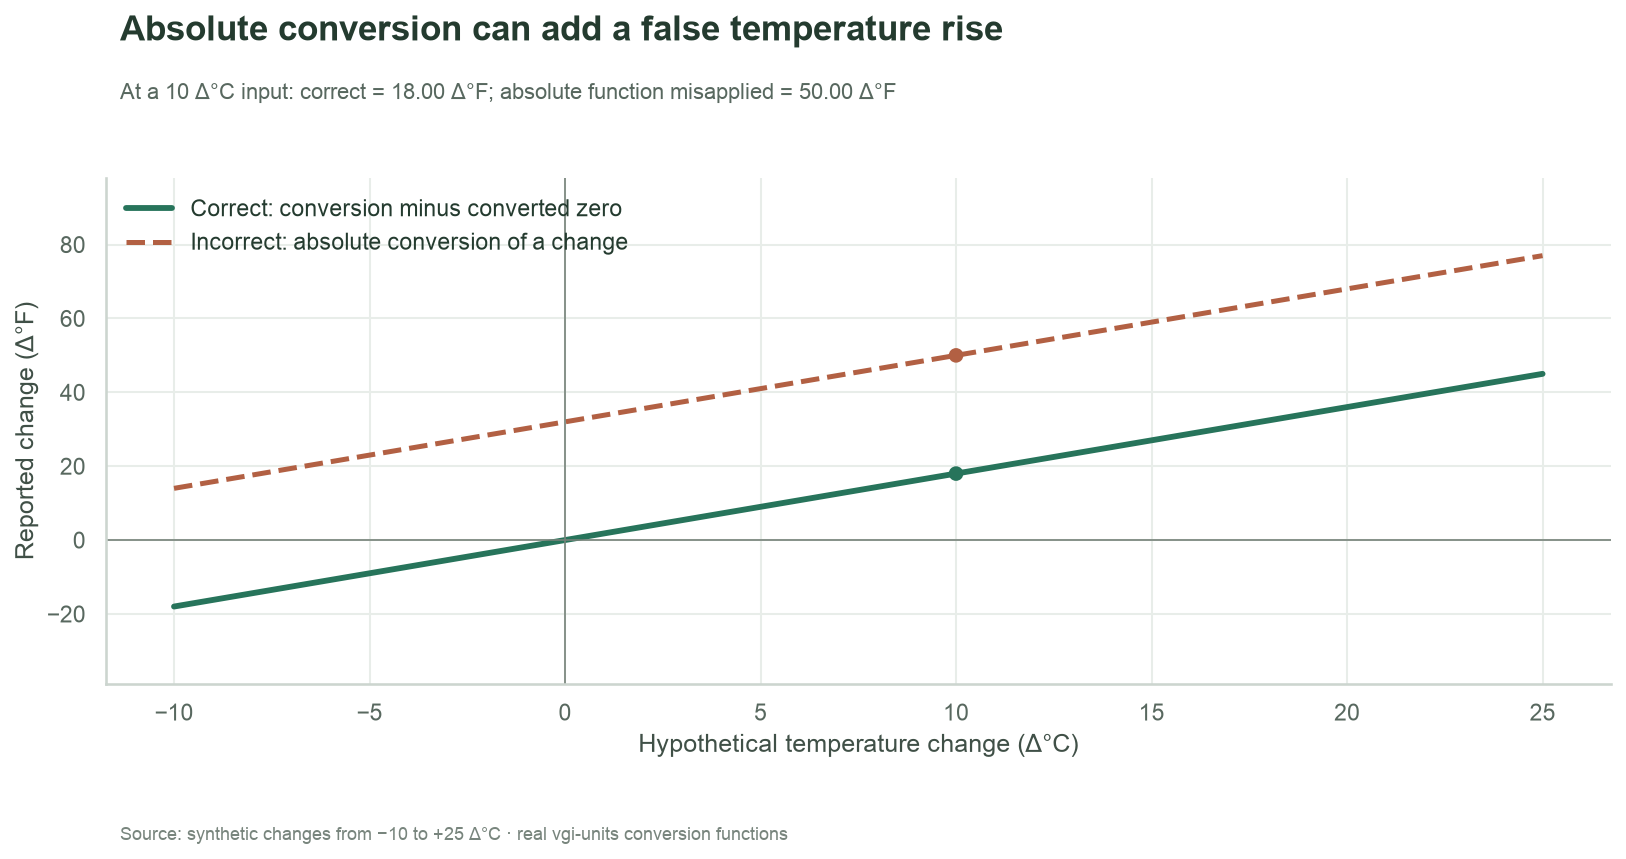

In [21]:
fig, ax = plt.subplots(figsize=(11, 5.7))
ax.plot(
    difference_curve.change_c,
    difference_curve.correct_difference,
    color="#27745B",
    label="Correct: conversion minus converted zero",
    lw=2.8,
)
ax.plot(
    difference_curve.change_c,
    difference_curve.absolute_misapplied,
    color="#B26043",
    linestyle="--",
    label="Incorrect: absolute conversion of a change",
    lw=2.4,
)
ax.axhline(0, color="#758279", linewidth=0.8)
ax.axvline(0, color="#758279", linewidth=0.8)
probe = difference_curve.loc[difference_curve.change_c == 10].iloc[0]
ax.scatter(
    [10, 10],
    [probe.correct_difference, probe.absolute_misapplied],
    c=["#27745B", "#B26043"],
    zorder=4,
)
ax.set(
    xlabel="Hypothetical temperature change (Δ°C)",
    ylabel=f"Reported change (Δ{REPORT_TEMP_UNIT})",
)
ax.legend(loc="upper left")
ax.margins(y=0.22)
chart(
    fig,
    "Absolute conversion can add a false temperature rise",
    f"At a 10 Δ°C input: correct = {probe.correct_difference:.2f} Δ{REPORT_TEMP_UNIT}; "
    f"absolute function misapplied = {probe.absolute_misapplied:.2f} Δ{REPORT_TEMP_UNIT}",
    source="Source: synthetic changes from −10 to +25 Δ°C · real vgi-units conversion functions",
)

In [22]:
probe = difference_curve.loc[difference_curve.change_c == 10].iloc[0]
prose(
    f"A **10 Δ°C** rise becomes **{probe.correct_difference:.2f} Δ{REPORT_TEMP_UNIT}**. "
    f"Passing that same numeral to the absolute conversion produces **{probe.absolute_misapplied:.2f}**; "
    f"the resulting error is **{probe.offset_error:+.2f} Δ{REPORT_TEMP_UNIT}** at every point in this curve. "
    + (
        "The lines overlap because source and target scales are both Celsius. That special case can hide the mistake; choose °F or K to reveal it. "
        if np.isclose(probe.offset_error, 0)
        else "Even a zero change would become nonzero under the wrong function. "
    )
    + "Unit compatibility cannot detect this semantic error: the caller must specify whether the number is an absolute quantity or a difference."
)

A **10 Δ°C** rise becomes **18.00 Δ°F**. Passing that same numeral to the absolute conversion produces **50.00**; the resulting error is **+32.00 Δ°F** at every point in this curve. Even a zero change would become nonzero under the wrong function. Unit compatibility cannot detect this semantic error: the caller must specify whether the number is an absolute quantity or a difference.

## Check the relationships, then change one parameter

These checks use the returned worker results: conversion round trips, agreement
with base units, offset cancellation and audit coverage. They allow ordinary
binary64 rounding and do not assert a site ranking. The values shown in the
report are not claims about instrument precision.

In [23]:
%%sql validation <<
SELECT
  (SELECT count(*) = count(DISTINCT reading_id) FROM raw_readings) AS unique_reading_ids,
  (SELECT count(*) FROM raw_readings) = (SELECT count(*) FROM audited_readings) AS all_rows_audited,
  (SELECT count(*) FROM normalized_readings) =
      (SELECT count(*) FROM audited_readings WHERE status = 'accepted') AS accepted_rows_accounted,
  NOT EXISTS (SELECT 1 FROM normalized_readings WHERE status <> 'accepted') AS rejected_rows_excluded,
  NOT EXISTS (
    SELECT site, metric FROM normalized_readings WHERE record_kind = 'operating'
    GROUP BY site, metric HAVING count(*) > 1
  ) AS unique_operating_metrics,
  (SELECT bool_and(report_value IS NOT NULL AND base_value IS NOT NULL)
      FROM normalized_readings) AS accepted_conversions_complete,
  (SELECT bool_and(abs(units.main.convert(report_value, report_unit, source_unit) - source_value)
       <= 1e-9 * greatest(1.0, abs(source_value))) FROM normalized_readings) AS round_trips_agree,
  (SELECT bool_and(abs(units.main.to_base(report_value, report_unit) - base_value)
       <= 1e-9 * greatest(1.0, abs(base_value))) FROM normalized_readings) AS base_values_agree,
  (SELECT bool_and(abs(rise_report - rise_from_endpoints) <= 1e-9 * greatest(1.0, abs(rise_report)))
      FROM thermal_report) AS temperature_offsets_cancel,
  (SELECT max(absolute_misapplied - correct_difference) - min(absolute_misapplied - correct_difference)
      < 1e-9 FROM difference_comparison) AS offset_error_is_constant;

In [24]:
display(validation.T.rename(columns={0: "passed"}))
assert validation.notna().all().all(), (
    "A required validation has no data; inspect coverage above."
)
assert validation.astype(bool).all().all(), "A conversion or audit invariant failed."
prose(
    f"**All {validation.shape[1]} relationship checks passed.** "
    "The audit and report agree, and the two ways of computing a temperature rise agree within tolerance."
)

,passed
unique_reading_ids,True
all_rows_audited,True
accepted_rows_accounted,True
rejected_rows_excluded,True
unique_operating_metrics,True
accepted_conversions_complete,True
round_trips_agree,True
base_values_agree,True
temperature_offsets_cancel,True
offset_error_is_constant,True


**All 10 relationship checks passed.** The audit and report agree, and the two ways of computing a temperature rise agree within tolerance.

### Focused experiment: report the same samples in Kelvin

Change only **`REPORT_TEMP_UNIT = "K"`**, then restart and run all. Before running,
predict which outputs should change. Absolute temperatures move to the Kelvin
scale; temperature rises should retain their physical size and site ordering.
Pressure, volume and input eligibility should remain identical.

Compare the paired-temperature chart and the **10 Δ°C** callout in the last
chart. A Kelvin temperature rise has the same numerical size as a Celsius rise,
while an absolute Celsius temperature needs the Kelvin offset. The dashed curve
should therefore expose a different offset error from the Fahrenheit run.

This experiment changes presentation, not the synthetic measurements. It cannot
validate the input sensors, pressure reference, or physical performance of a
skid. Reset **`REPORT_TEMP_UNIT = "°F"`** to recover the saved default report.
[The runner](README.md#change-the-reporting-scale) can save the experiment as a
separate executed copy.

In [25]:
con.close()

---

<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="210"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Notebook guide](README.md)